# Intelligent Phishing Campaign Behaviour Detection Using Sequential Models
**Project 17 - Chain factor graph, sum-product and Viterbi**

**Workflow:** Dataset → preprocessing → sequence construction → model formulation → algorithm implementation → inference/estimation → evaluation → visualization → interpretation.

> **Disclosure.** The *emails* (timestamps, sender domains, URL flag, urgency keywords) are **real** (CEAS-08). The hidden **stage labels and all non-email events** (clicks, credential submission, logins, mailbox rules...) are **synthetic**, produced by a documented generator (`src/config.py`, `src/generate_data.py`), because no public dataset contains campaign stages. This is an **educational prototype, not a production security system.**

**Reproducibility:** fixed seeds; put `CEAS_08.csv` in `data/raw/` and run all cells.

In [1]:
import sys, inspect, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import *
from src.preprocess import load_ceas, email_features
from src.generate_data import build_dataset, to_sequences, generate_episodes
from src.hmm import ChainFactorGraph, sum_product, viterbi, estimate_parameters
from src.baselines import HmmlearnReference
from src import evaluate as ev
from src.pipeline import fit_models, run_inference, evaluate_set, perturb_obs
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
RAW = ROOT / "data/raw/CEAS_08.csv"
assert RAW.exists(), "Place CEAS_08.csv in data/raw/"
print("seed =", SEED)

seed = 42


## 1. Dataset
CEAS-08 (phishing = 1, benign = 0) has sender, receiver, date, subject, body, URL flag. Almost all messages fall in one week (4-10 Aug 2008), so a chronological split is meaningful.

rows: 39154 | label counts: {1: 21842, 0: 17312}
unparseable dates: 15
date range (raw, incl. corrupt headers): 1980-01-04 05:39:00+00:00 -> 2100-05-27 19:54:05+00:00
inside 4-10 Aug 2008 window: 38631 (98.7%)


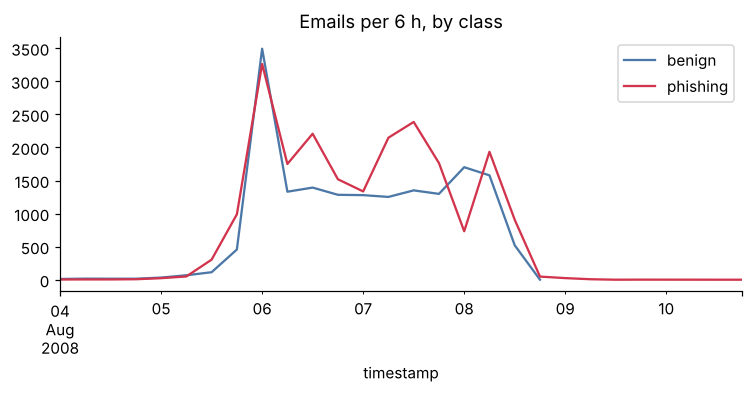

In [2]:
raw = pd.read_csv(RAW)
raw["timestamp"] = pd.to_datetime(raw["date"], errors="coerce", utc=True)
print("rows:", len(raw), "| label counts:", raw.label.value_counts().to_dict())
print("unparseable dates:", raw.timestamp.isna().sum())
ok = raw.dropna(subset=["timestamp"])
print("date range (raw, incl. corrupt headers):", ok.timestamp.min(), "->", ok.timestamp.max())
win = ok[(ok.timestamp >= "2008-08-04") & (ok.timestamp < "2008-08-11")]
print(f"inside 4-10 Aug 2008 window: {len(win)} ({len(win)/len(raw):.1%})")
fig, ax = plt.subplots(figsize=(8, 3))
for lab, c in [(0, "#4c78a8"), (1, "#d1344c")]:
    win[win.label == lab].timestamp.dt.floor("6h").value_counts().sort_index().plot(ax=ax, color=c, label=["benign", "phishing"][lab])
ax.set_title("Emails per 6 h, by class"); ax.legend(); plt.show()

## 2. Preprocessing
Parse dates, keep the dense window, drop duplicates, sort by time. Each email becomes one of four **real event categories** from two features: contains a URL, contains urgency/credential keywords.

In [3]:
ceas = load_ceas(RAW)
feat = email_features(ceas)
print(f"after cleaning: {len(ceas)} emails (from {ceas.attrs['rows_raw']} raw rows)")
mix = feat.groupby("label").email_obs.value_counts(normalize=True).unstack().round(3)
mix.columns = [OBS[c] for c in mix.columns]; mix.index = ["benign", "phishing"]
mix

after cleaning: 38631 emails (from 39154 raw rows)


,email_clean,email_urgent_kw,email_url,email_url_urgent
benign,0.251,0.095,0.432,0.222
phishing,0.208,0.112,0.584,0.096


## 3. Sequence construction
* Sample 3,000 real emails per class (fixed seed) and **sort by time**.
* **Chronological split** by email time: earliest 70% train, next 15% validation, last 15% test.
* Each real email *seeds one campaign episode*: the synthetic generator draws a hidden stage path (6 stages) of 8-16 events, emits non-email events, and inserts the **real email event at its real timestamp**.
* Phishing seeds start the chain at Recon/Delivery and may progress, skip or fizzle; benign seeds stay in Benign (with hard negatives such as ordinary clicks and logins).

In [4]:
events, episodes, gens, seeds = build_dataset(feat, N_PER_CLASS, SEED)
sq = {sp: to_sequences(events[events.split == sp]) for sp in ("train", "val", "test")}
print(events.shape, "events;", len(episodes), "episodes")
print(episodes.groupby("split").agg(episodes=("campaign_id", "size"), first=("seed_time", "min"), last=("seed_time", "max"),
                                    compromise_rate=("reaches_harvest", "mean")).round(3))
# ---- leakage checks ----
t = episodes.groupby("split").seed_time.agg(["min", "max"])
assert t.loc["train", "max"] <= t.loc["val", "min"] and t.loc["val", "max"] <= t.loc["test", "min"], "chronology violated"
print("OK: train < val < test in time, no overlap")
cid = episodes[(episodes.split == "test") & episodes.reaches_takeover].campaign_id.iloc[3]
events[events.campaign_id == cid][["step", "timestamp", "event", "true_stage"]].assign(
    true_stage=lambda d: d.true_stage.map(dict(enumerate(STATES))))

(72013, 7) events; 6000 episodes
       episodes                     first                      last  \
split                                                                 
test        900 2008-08-08 03:50:04+00:00 2008-08-09 07:14:10+00:00   
train      4200 2008-08-04 00:58:07+00:00 2008-08-07 16:02:38+00:00   
val         900 2008-08-07 16:03:17+00:00 2008-08-08 03:49:32+00:00   

       compromise_rate  
split                   
test             0.213  
train            0.227  
val              0.199  
OK: train < val < test in time, no overlap


/tmp/ipykernel_293/2920182323.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  compromise_rate=("reaches_harvest", "mean")).round(3))


,step,timestamp,event,true_stage
61523,0,2008-08-08 04:20:25+00:00,email_url,Delivery
61524,1,2008-08-08 05:07:16.030036926+00:00,link_clicked,Delivery
61525,2,2008-08-08 05:54:32.941365719+00:00,landing_page_visit,Lure/Click
61526,3,2008-08-08 06:38:42.611910820+00:00,credential_submitted,Credential Harvest
61527,4,2008-08-08 07:27:59.042486906+00:00,normal_activity,Credential Harvest
61528,5,2008-08-08 10:17:02.542713165+00:00,link_clicked,Takeover
61529,6,2008-08-08 11:30:02.334908247+00:00,bulk_forward,Takeover
61530,7,2008-08-08 11:40:01.432852507+00:00,new_ip_login,Takeover


## 4. Model formulation - chain factor graph
Hidden stages $Z_1..Z_T$ (K=6), observed events $X_1..X_T$ (M=12):

$$p(z,x)=\phi_0(z_1)\prod_{t=1}^{T}\phi_e(z_t,x_t)\prod_{t=2}^{T}\psi(z_{t-1},z_t)$$

* $\phi_0$ prior (vector $\pi$), $\psi$ transition factor (matrix $A$), $\phi_e$ emission factor (matrix $B$).
* **Sum-product** (forward-backward message passing) → marginals $P(Z_t\mid X)$. **Max-product = Viterbi** → single best path.
* Parameters are estimated **only from the training split** by counting with Laplace smoothing.

## 5. Algorithm implementation (from scratch, NumPy)

In [5]:
print(inspect.getsource(sum_product)); print(inspect.getsource(viterbi))

def sum_product(pi, A, B, obs):
    """Sum-product on the chain.

    Returns
    -------
    filtered : (T,K)  P(Z_t | X_1..X_t)   forward messages normalised  (online / alerting)
    smoothed : (T,K)  P(Z_t | X_1..X_T)   forward x backward           (offline / investigation)
    loglik   : float  log P(X_1..X_T)
    """
    phi = unary_factors(B, obs)
    T, K = phi.shape
    alpha = np.zeros((T, K))
    c = np.zeros(T)                      # scaling constants (normalisers of forward messages)
    a = pi * phi[0]
    c[0] = max(a.sum(), TINY)
    alpha[0] = a / c[0]
    for t in range(1, T):                # variable -> factor -> variable message
        a = (alpha[t - 1] @ A) * phi[t]
        c[t] = max(a.sum(), TINY)
        alpha[t] = a / c[t]
    beta = np.ones((T, K))               # backward messages
    for t in range(T - 2, -1, -1):
        beta[t] = (A @ (phi[t + 1] * beta[t + 1])) / c[t + 1]
    smoothed = alpha * beta
    smoothed /= smoothed.sum(axis=1, keepdims=True)
   

In [6]:
# Verify against brute-force enumeration on a tiny random HMM
import itertools
r = np.random.default_rng(0)
nrm = lambda a: a / a.sum(-1, keepdims=True)
pi_, A_, B_ = nrm(r.random(3) + .1), nrm(r.random((3, 3)) + .1), nrm(r.random((3, 4)) + .1)
x = [0, 2, 1, 3, 0]
def joint(z):
    p = pi_[z[0]] * B_[z[0], x[0]]
    for t in range(1, len(z)): p *= A_[z[t-1], z[t]] * B_[z[t], x[t]]
    return p
paths = list(itertools.product(range(3), repeat=len(x))); w = np.array([joint(z) for z in paths])
marg = np.zeros((len(x), 3))
for p, z in zip(w, paths):
    for t, s in enumerate(z): marg[t, s] += p
_, gamma, ll = sum_product(pi_, A_, B_, x)
print("sum-product == brute force:", np.allclose(gamma, marg / w.sum()), "| loglik ok:", np.isclose(ll, np.log(w.sum())))
print("viterbi == brute force   :", list(viterbi(pi_, A_, B_, x)[0]) == list(max(paths, key=joint)))

sum-product == brute force: True | loglik ok: True
viterbi == brute force   : True


## 6. Estimation (training split only)

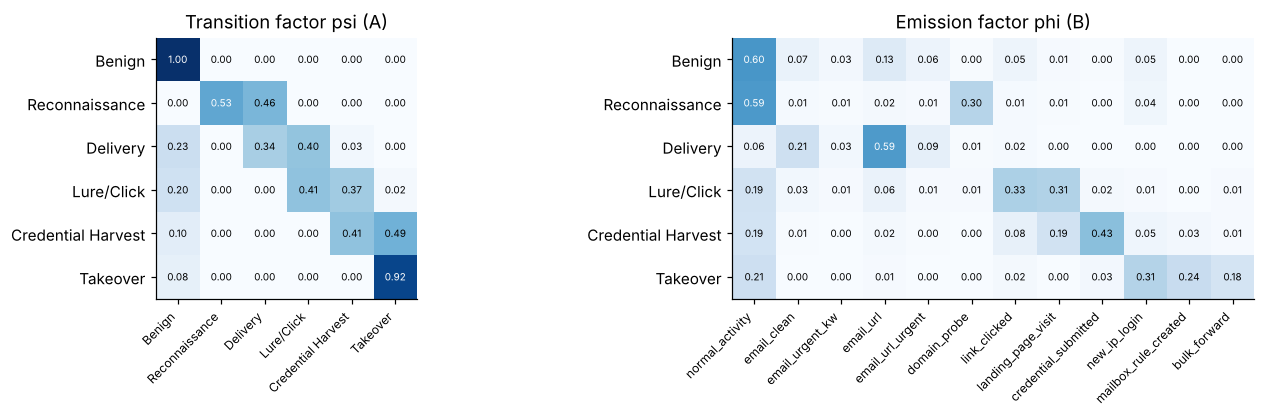

In [7]:
graph, base = fit_models(sq["train"])
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, M_, xl, t in [(axs[0], graph.A, STATES, "Transition factor psi (A)"), (axs[1], graph.B, OBS, "Emission factor phi (B)")]:
    im = ax.imshow(M_, cmap="Blues", vmin=0, vmax=1); ax.set_title(t)
    ax.set_yticks(range(K)); ax.set_yticklabels(STATES); ax.set_xticks(range(len(xl))); ax.set_xticklabels(xl, rotation=45, ha="right", fontsize=8)
    for i in range(K):
        for j in range(len(xl)): ax.text(j, i, f"{M_[i,j]:.2f}", ha="center", va="center", fontsize=6.5, color="white" if M_[i,j] > .5 else "black")
plt.tight_layout(); plt.show()

## 7. Inference - stage probabilities and the decoded path for one campaign

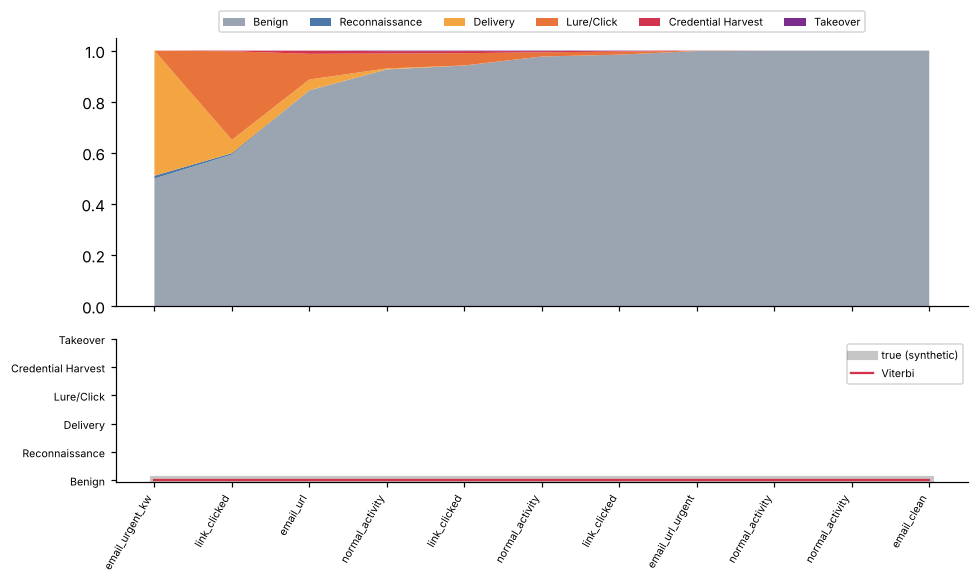

In [8]:
s = sq["test"][3]
filt, smooth, ll = graph.infer(s["obs"]); vit, _ = graph.decode(s["obs"])
fig, axs = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True, gridspec_kw={"height_ratios": [3, 1.6]})
COL = ["#9aa5b1", "#4c78a8", "#f2a541", "#e8743b", "#d1344c", "#7b2d8e"]
axs[0].stackplot(range(len(s["obs"])), smooth.T, labels=STATES, colors=COL); axs[0].legend(ncol=6, fontsize=7, loc="lower center", bbox_to_anchor=(.5, 1))
axs[1].step(range(len(vit)), s["states"], where="mid", lw=6, color="#444", alpha=.3, label="true (synthetic)")
axs[1].step(range(len(vit)), vit, where="mid", color="#d1344c", label="Viterbi"); axs[1].legend(fontsize=7)
axs[1].set_yticks(range(K)); axs[1].set_yticklabels(STATES, fontsize=7)
axs[1].set_xticks(range(len(vit))); axs[1].set_xticklabels([OBS[o] for o in s["obs"]], rotation=60, ha="right", fontsize=7)
plt.tight_layout(); plt.show()

## 8. Evaluation
**Alert rule:** raise an alert at the first step where $P(Z_t\in\{\text{Harvest},\text{Takeover}\}\mid X_{1:t})>\tau$ (filtered = online). A campaign is *positive* if its true path reaches Credential Harvest. τ is **tuned on the validation split** for each method, then frozen for test. Baselines: per-event Naive Bayes, logistic regression on the current event and on a 3-event window, and a simple SOC-style rule. Reference implementation: `hmmlearn`.

In [9]:
inf = {sp: run_inference(graph, base, sq[sp]) for sp in ("val", "test")}
y_val = np.array([(x["states"] >= 4).any() for x in sq["val"]])
taus = {n: (0.5 if n.startswith("Rule") else ev.choose_threshold(y_val, [ev.campaign_score(v) for v in sc])) for n, sc in inf["val"]["score"].items()}
res = evaluate_set(sq["test"], inf["test"], taus)
stage = pd.DataFrame({n: {"accuracy": m["accuracy"], "macro_F1": m["macro_f1"]} for n, m in res["stage"].items()}).T.round(3)
det = pd.DataFrame({n: {"precision": m["precision"], "recall": m["recall"], "F1": m["f1"], "tau": m["tau"],
                        "alerted_before_takeover": res["lead"][n]["alerted_before_takeover"],
                        "median_lead_min": res["lead"][n]["median_lead_minutes"]} for n, m in res["detect"].items()}).T.round(3)
print("STAGE DECODING (test, per step)"); display(stage)
print("COMPROMISE DETECTION (test, campaign level)"); display(det)

STAGE DECODING (test, per step)


,accuracy,macro_F1
HMM Viterbi (ours),0.911,0.775
HMM sum-product argmax (ours),0.913,0.786
NaiveBayes(event),0.807,0.464
LogReg(event),0.807,0.464
LogReg(window=3),0.844,0.636


COMPROMISE DETECTION (test, campaign level)


,precision,recall,F1,tau,alerted_before_takeover,median_lead_min
HMM filtered (ours),0.959,0.859,0.907,0.878,0.423,80.456
HMM smoothed (ours),0.966,0.875,0.918,0.586,0.878,89.325
NaiveBayes(event),0.729,0.911,0.810,0.419,0.609,88.684
LogReg(event),0.793,0.776,0.784,0.786,0.096,73.992
LogReg(window=3),0.942,0.839,0.887,0.829,0.365,88.684
Rule (cred/rule/forward),0.729,0.911,0.810,0.500,0.609,88.684


In [10]:
# Reference implementation check (hmmlearn loaded with the SAME parameters)
ref = HmmlearnReference(graph.pi, graph.A, graph.B)
te_obs = [x["obs"] for x in sq["test"]]
rp, rq = ref.decode_all(te_obs)
own_p = inf["test"]["pred"]["HMM Viterbi (ours)"]; own_q = inf["test"]["smoothed"]
print("Viterbi path agreement with hmmlearn :", np.mean(np.concatenate(own_p) == np.concatenate(rp)))
print("max |posterior difference|           :", max(np.abs(a - b).max() for a, b in zip(own_q, rq)))
print("max |loglik difference| (200 seqs)   :", max(abs(graph.infer(o)[2] - ref.loglik(o)) for o in te_obs[:200]))

Viterbi path agreement with hmmlearn : 1.0
max |posterior difference|           : 5.10702591327572e-15


max |loglik difference| (200 seqs)   : 2.1316282072803006e-14


In [11]:
# Per-stage detail for our Viterbi decoder
m = res["stage"]["HMM Viterbi (ours)"]["per_stage"]
pd.DataFrame({"precision": m["precision"], "recall": m["recall"], "F1": m["f1"], "support": m["support"]}, index=STATES).round(3)

,precision,recall,F1,support
Benign,0.936,0.977,0.956,8215
Reconnaissance,0.953,0.742,0.834,326
Delivery,0.748,0.495,0.596,685
Lure/Click,0.668,0.635,0.651,479
Credential Harvest,0.782,0.618,0.690,301
Takeover,0.907,0.940,0.923,837


## 9. Visualization

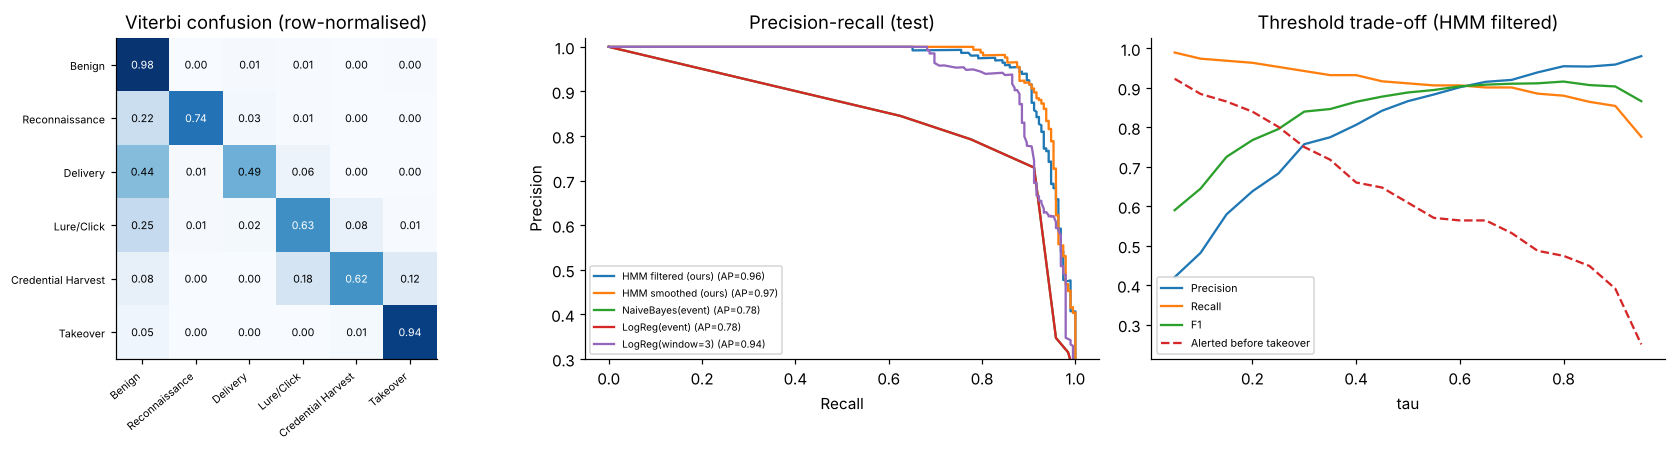

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
cm = np.array(res["stage"]["HMM Viterbi (ours)"]["confusion"], float); cm /= cm.sum(1, keepdims=True)
axs[0].imshow(cm, cmap="Blues", vmin=0, vmax=1); axs[0].set_title("Viterbi confusion (row-normalised)")
axs[0].set_xticks(range(K)); axs[0].set_yticks(range(K)); axs[0].set_xticklabels(STATES, rotation=40, ha="right", fontsize=7); axs[0].set_yticklabels(STATES, fontsize=7)
for i in range(K):
    for j in range(K): axs[0].text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cm[i,j] > .5 else "black")
y_te = np.array([(x["states"] >= 4).any() for x in sq["test"]])
for n, sc in inf["test"]["score"].items():
    if n.startswith("Rule"): continue
    p, r, ap = ev.pr_curve(y_te, [ev.campaign_score(v) for v in sc]); axs[1].plot(r, p, label=f"{n} (AP={ap:.2f})")
axs[1].set_xlabel("Recall"); axs[1].set_ylabel("Precision"); axs[1].set_title("Precision-recall (test)"); axs[1].legend(fontsize=6.5); axs[1].set_ylim(.3, 1.02)
rows = []
for tau in np.arange(.05, .99, .05):
    sc = inf["test"]["score"]["HMM filtered (ours)"]
    d = ev.prf(y_te, [ev.campaign_score(v) for v in sc], tau); l = ev.lead_time_stats(sq["test"], sc, tau)
    rows.append((tau, d["precision"], d["recall"], d["f1"], l["alerted_before_takeover"]))
rows = np.array(rows)
for i, nme in enumerate(["Precision", "Recall", "F1", "Alerted before takeover"]): axs[2].plot(rows[:, 0], rows[:, i+1], label=nme, ls="--" if i == 3 else "-")
axs[2].set_xlabel("tau"); axs[2].set_title("Threshold trade-off (HMM filtered)"); axs[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Robustness: noisy telemetry and unseen stage skipping
The synthetic data come from a chain, so the HMM is well matched. To check this is not an artefact, we (a) corrupt a fraction of test events and (b) regenerate the test set with a **different transition matrix** with far more stage skipping, while keeping the trained models and thresholds fixed.

In [13]:
rng = np.random.default_rng(SEED + 7); rows = []
for eps in (0.0, 0.1, 0.2, 0.3, 0.4):
    s2 = perturb_obs(sq["test"], eps, rng); r = evaluate_set(s2, run_inference(graph, base, s2), taus)
    rows.append({"corruption": eps, **{f"{n} F1": r["detect"][n]["f1"] for n in ("HMM filtered (ours)", "LogReg(window=3)", "Rule (cred/rule/forward)")},
                 "HMM Viterbi acc": r["stage"]["HMM Viterbi (ours)"]["accuracy"], "LogReg(w3) acc": r["stage"]["LogReg(window=3)"]["accuracy"]})
display(pd.DataFrame(rows).round(3))
te_seeds = seeds[seeds.split == "test"]
ev_sk, _ = generate_episodes(te_seeds, gens["test"], np.random.default_rng(SEED + 9), A=A_SKIP, id_prefix="S")
s_sk = to_sequences(ev_sk); r = evaluate_set(s_sk, run_inference(graph, base, s_sk), taus)
print("UNSEEN STAGE SKIPPING (test regenerated with A_SKIP)")
display(pd.DataFrame({"stage_acc": {n: m["accuracy"] for n, m in r["stage"].items()},
                      }).round(3).join(pd.DataFrame({"detect_F1": {n: m["f1"] for n, m in r["detect"].items()}}).round(3), how="outer"))

,corruption,HMM filtered (ours) F1,LogReg(window=3) F1,Rule (cred/rule/forward) F1,HMM Viterbi acc,LogReg(w3) acc
0,0.0,0.907,0.887,0.810,0.911,0.844
1,0.1,0.824,0.802,0.587,0.887,0.814
2,0.2,0.791,0.710,0.466,0.849,0.779
3,0.3,0.735,0.678,0.449,0.818,0.746
4,0.4,0.634,0.550,0.416,0.782,0.706


UNSEEN STAGE SKIPPING (test regenerated with A_SKIP)


,stage_acc,detect_F1
HMM Viterbi (ours),0.918,NaN
HMM filtered (ours),NaN,0.899
HMM smoothed (ours),NaN,0.894
HMM sum-product argmax (ours),0.915,NaN
LogReg(event),0.788,0.840
LogReg(window=3),0.837,0.901
NaiveBayes(event),0.788,0.852
Rule (cred/rule/forward),NaN,0.852


## 10. Interpretation
* **Sequence context helps.** The sequential HMM decodes stages more accurately than every non-sequential baseline, and the gap is largest in the *middle* stages (Delivery, Lure/Click, Credential Harvest), where single events are ambiguous: `normal_activity` appears in every stage, and clicks or new-IP logins also occur in benign activity.
* **Detection:** the online HMM alert reaches high precision and recall for compromise, clearly beating the single-event rule and Naive Bayes, and slightly beating a 3-event logistic-regression window. A window model is a strong baseline when the generator is this simple.
* **Where it fails:** Delivery, Lure/Click and Credential Harvest are confused with their neighbours (see confusion matrix), mostly when telemetry is missing. Under unseen stage skipping the HMM's *detection* edge disappears (F1 0.899 vs 0.901 for the window model), but it keeps its *stage-decoding* lead (accuracy 0.918 vs 0.837).
* **Threshold matters operationally:** the F1-optimal τ is conservative, so alerts often come *at or after* credential submission. A lower τ gives earlier warning at the cost of precision (see trade-off plot and the dashboard slider).
* **Limits of the evidence:** stage labels and non-email events are synthetic and generated from a chain, which favours a chain model. Absolute numbers should not be read as real-world performance; the *relative* comparison and the robustness trends are the useful result. The real CEAS emails supply only weak signals (phishing and benign mixes differ moderately).
* **Not a production system.** Educational prototype.